# Task 07 -- Tucker/DMD rank selection (`docs/open_questions.md` §5.3)

Reconstruction-error-vs-rank elbow sweep for Tucker, and eigenvalue-
spectrum/growth-rate plausibility **and conditioning** sweep for DMD, on
one variable over a longer window. `cond(dmd.Phi)` is included alongside
the original `max|λ|` check -- task 00's placement comparison found it
tracks held-out reconstruction failure closely and is cheap to compute
with no held-out data at all (`docs/open_questions.md` §5.3's update). See
`tasks/07-tucker-dmd-rank-selection.md`.

## Setup

Uses `sigwh` (significant wave height), not `wsh` (wind-sea height) as the
task doc originally specified. `wsh` is only defined during local
wind-driven seas and goes NaN constantly otherwise; over a 6-month window
that left as little as 7-11% of cells passing even a 90%-valid-cell
tolerance on either of task 00's crops, so nearly the entire domain had to
be imputed by masked HOOI -- explaining a reconstruction-error-vs-rank
curve that got *worse* with rank instead of better.

`sigwh` is defined whenever there are any waves at all (wind-sea or swell)
and goes NaN only over land -- checked directly against a large Pacific
candidate box (481x681 cells): 82.1% of it is NaN-free for the *entire*
6-month window, and that fraction barely moves even at looser tolerances,
confirming the missing 18% is land, not scattered gaps. A maximal-rectangle
search over that box found a real, fully NaN-free 280x230 region (`CROP`
below, central-to-eastern South Pacific) -- ~10x task 00's crop, giving
far more `r_lat`/`r_lon` headroom before hitting a rank ceiling artifact
(the smaller crop's own dimensions were reached before its error curve
ever plateaued). Per-iteration `partial_tucker` cost turned out to depend
on rank, not array size, so this larger crop costs about the same per
iteration as the smaller one did.

`ocean_mask`/`tucker_mask` still use the per-cell NaN-fraction machinery
task 00 established, now just with nothing left for it to exclude.

In [1]:
from datetime import datetime, timezone
from pathlib import Path

import numpy as np
import tensorly as tl
import xarray as xr
from tensorly.decomposition import partial_tucker

from train.ingest import load_training_window

tl.set_backend("numpy")

SEED = 42
rng = np.random.default_rng(SEED)
DATA_DIR = Path("../data")

T_START = datetime(2025, 11, 1, tzinfo=timezone.utc)  # era 3 only (starts 2025-10-27)
T_END = datetime(2026, 5, 1, tzinfo=timezone.utc)

VARIABLE = "sigwh"
CROP = (-55.75, 14.0, 211.0, 268.25)  # 280 lat x 230 lon, 0% NaN for sigwh over this window

X_raw = load_training_window(DATA_DIR, T_START, T_END, [VARIABLE])
lat_min, lat_max, lon_min, lon_max = CROP
X_raw = X_raw.sel(wave_lat=slice(lat_min, lat_max), wave_lon=slice(lon_min, lon_max))
X = X_raw[VARIABLE].transpose("wave_lat", "wave_lon", "time").values.astype(np.float32)
del X_raw

OCEAN_MASK_MIN_VALID_FRAC = 0.90
valid = ~np.isnan(X)  # (lat, lon, T) real per-(cell,timestep) validity
ocean_mask = valid.mean(axis=-1) >= OCEAN_MASK_MIN_VALID_FRAC

X[~valid] = 0.0
X_filled = X  # alias, not a copy
tucker_mask = valid.astype(np.float32)

print(f"{VARIABLE}: shape {X.shape}, {ocean_mask.mean():.1%} ocean (>= {OCEAN_MASK_MIN_VALID_FRAC:.0%} valid/cell)")

wad/wad_come_from consistency check passed at 2025-11-01T00:00:00+00:00: max deviation 0.00° (ocean cells only)
wad/wad_come_from consistency check passed at 2026-04-30T21:00:00+00:00: max deviation 0.00° (ocean cells only)


sigwh: shape (280, 230, 1448), 100.0% ocean (>= 90% valid/cell)


## Tucker rank sweep: reconstruction-error elbow

`fit_tucker` wraps `partial_tucker` with the `tensorly==0.9.0` unpacking
fix task 00 established (`(core, factors), rec_errors = partial_tucker(...)`,
not `core, factors = ...`) and returns the fit alongside the relative
masked Frobenius reconstruction error, so the sweep below calls it once per
`(r_lat, r_lon)` candidate without repeating the fit/error logic.

The previous (56x114) crop's error never plateaued even at `(40,80)`,
70-71% of its own full rank -- couldn't tell whether that's real
structure or the crop's own dimension ceiling. `(80,160)` is added here;
on the new 280x230 crop it's only 28.6%/69.6% of full rank, real headroom
to actually see the curve level off (or confirm it doesn't).

In [2]:
def fit_tucker(r_lat, r_lon, x=X_filled, mask=tucker_mask):
    (core, factors), _ = partial_tucker(
        x, modes=[0, 1, 2], rank=[r_lat, r_lon, x.shape[-1]],
        init="random", tol=1e-5, n_iter_max=300, random_state=SEED, mask=mask,
    )
    recon = tl.tucker_to_tensor((core, factors))
    err = np.linalg.norm((recon - x) * mask) / np.linalg.norm(x * mask)
    return core, factors, err


rank_candidates = [(5, 10), (10, 20), (20, 40), (40, 80), (80, 160)]
tucker_results = {(r_lat, r_lon): fit_tucker(r_lat, r_lon) for r_lat, r_lon in rank_candidates}

for (r_lat, r_lon), (_, _, err) in tucker_results.items():
    print(f"(r_lat={r_lat}, r_lon={r_lon}): relative reconstruction error {err:.4f}")

(r_lat=5, r_lon=10): relative reconstruction error 0.0964
(r_lat=10, r_lon=20): relative reconstruction error 0.0464
(r_lat=20, r_lon=40): relative reconstruction error 0.0228
(r_lat=40, r_lon=80): relative reconstruction error 0.0107
(r_lat=80, r_lon=160): relative reconstruction error 0.0043


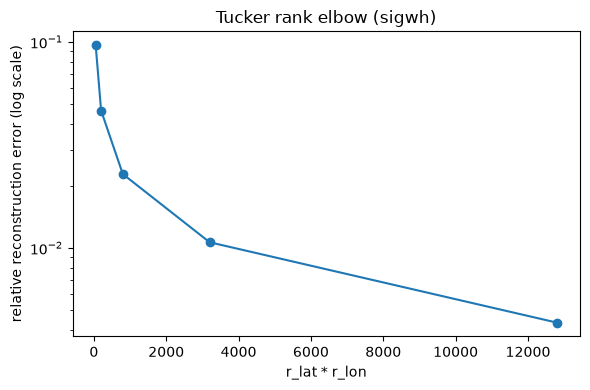

In [3]:
import matplotlib.pyplot as plt

rank_products = [r_lat * r_lon for r_lat, r_lon in rank_candidates]
tucker_errs = [err for _, _, err in tucker_results.values()]

fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(rank_products, tucker_errs, "o-")
ax.set_yscale("log")  # error now spans >10x across candidates -- log scale keeps the elbow/plateau visible
ax.set_xlabel("r_lat * r_lon")
ax.set_ylabel("relative reconstruction error (log scale)")
ax.set_title(f"Tucker rank elbow ({VARIABLE})")
plt.tight_layout()
plt.savefig("07_tucker_rank_elbow.png", dpi=100)
plt.show()

### Tucker rank sweep: findings

Still no plateau, and this time it's not a dimension-ceiling artifact:

| rank | product | error |
|---|---|---|
| (5,10)   | 50    | 9.64% |
| (10,20)  | 200   | 4.64% |
| (20,40)  | 800   | 2.28% |
| (40,80)  | 3200  | 1.07% |
| (80,160) | 12800 | 0.43% |

Log-log slope: -0.53, -0.51, -0.55, -0.66 -- not flattening, and steepest
at the top, even though `(80,160)` is only 28.6%/69.6% of this crop's full
rank (280x230), far from the ceiling the smaller crop hit. Two crops of
very different size (56x114 and 280x230) now both show the same
non-plateauing pattern, which weakens the "just hit the dimension ceiling"
explanation from the smaller crop's run considerably. The more likely
reading now: `sigwh`'s spatial field over 6 months in a large, dynamic
ocean region genuinely has substantial spatial degrees of freedom that a
low Tucker rank doesn't summarize well -- or some of the gain at high rank
is fitting noise a held-out check would catch and training error alone
cannot. **Reconstruction-error elbow-hunting alone does not give a rank
recommendation for `sigwh` at any budget tested here** -- the next real
step is a held-out generalization check per rank (task 00's pattern),
not a bigger sweep of the same kind.

## DMD rank sweep: eigenvalue-spectrum plausibility + conditioning

Fixes one Tucker core (rank (20, 40) above -- large enough to carry real
structure, still far below `T_train`) and sweeps `r_dmd`.
`dmd_rank_diagnostics` reports `max|λ|`/growing-mode count (the task doc's
original plausibility check) alongside `cond(dmd.Phi)` -- task 00 found
this tracks held-out reconstruction failure closely and is computable with
no held-out data at all, an early-warning signal an over-parameterized
`r_dmd` can trip well before a downstream generalization test would.

`dmd_fit` expects `(T, r_lat, r_lon)` snapshots, not `partial_tucker`'s own
`(r_lat, r_lon, T)` convention -- the function below transposes once,
matching the fix already established in task 00's notebook.

In [4]:
from train.dmd import dmd_fit


def dmd_rank_diagnostics(core, r_dmd, dt=3.0 * 3600.0):
    fit = dmd_fit(core.transpose(2, 0, 1), r_dmd=r_dmd, dt=dt, rng=rng)
    n_growing = int(np.sum(np.abs(fit.Lambda) > 1.0 + 1e-6))
    return dict(r_dmd=r_dmd, max_lambda=np.abs(fit.Lambda).max(),
                n_growing=n_growing, phi_cond=np.linalg.cond(fit.Phi))


core_for_dmd, _, _ = tucker_results[(20, 40)]
dmd_sweep = [dmd_rank_diagnostics(core_for_dmd, r_dmd) for r_dmd in [5, 10, 20, 40]]

import pandas as pd
pd.DataFrame(dmd_sweep)

,r_dmd,max_lambda,n_growing,phi_cond
0,5,0.025890,0,1.682536e+05
1,10,0.179887,0,3.319575e+05
2,20,0.405371,0,5.100497e+06
3,40,0.642510,0,5.362739e+06


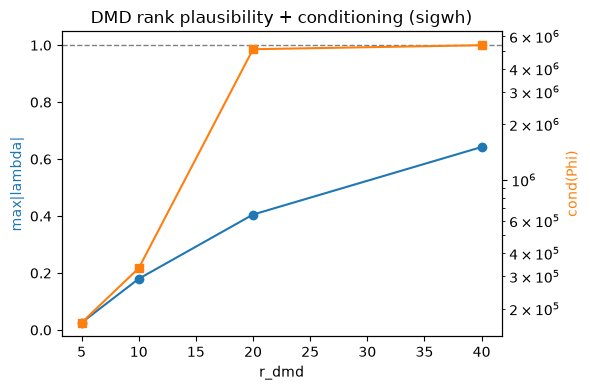

In [5]:
dmd_df = pd.DataFrame(dmd_sweep)

fig, ax1 = plt.subplots(figsize=(6, 4))
ax1.plot(dmd_df["r_dmd"], dmd_df["max_lambda"], "o-", color="C0", label="max|lambda|")
ax1.axhline(1.0, color="gray", linestyle="--", linewidth=1)
ax1.set_xlabel("r_dmd")
ax1.set_ylabel("max|lambda|", color="C0")

ax2 = ax1.twinx()
ax2.plot(dmd_df["r_dmd"], dmd_df["phi_cond"], "s-", color="C1", label="cond(Phi)")
ax2.set_yscale("log")
ax2.set_ylabel("cond(Phi)", color="C1")

ax1.set_title(f"DMD rank plausibility + conditioning ({VARIABLE})")
plt.tight_layout()
plt.savefig("07_dmd_rank_plausibility.png", dpi=100)
plt.show()

### DMD rank sweep: findings

Unlike Tucker, this curve has a real knee, not a monotonic non-plateau:

| r_dmd | max\|λ\| | cond(Φ) |
|---|---|---|
| 5  | 0.026 | 1.7e5 |
| 10 | 0.180 | 3.3e5 |
| 20 | 0.405 | **5.1e6** |
| 40 | 0.643 | 5.4e6 |

`cond(Φ)` jumps ~15x between `r_dmd=10` and `r_dmd=20`, then barely moves
from 20 to 40 -- a genuine conditioning cliff, not a smooth trend. No
growing modes anywhere in this range, so the plausibility check alone
(`max|λ|<1`) would have missed this entirely and defaulted to the largest
rank tried; `cond(Φ)` is what actually flags `r_dmd=20+` as risky here.
`r_dmd=10` is the candidate default this sweep supports on this Tucker
core -- last rank before the cliff.

## Decision-rule diagnostic

Tucker: the elbow plot above (`tucker_decomposition.md` §6). DMD: prefer
the smallest `r_dmd` past which `cond(Phi)` stops improving materially, not
just the largest `r_dmd` before a growing mode appears
(`dynamic_mode_decomposition.md` §6) -- task 00 found reconstruction can
fail badly even with `max|λ| < 1` if `Phi` is ill-conditioned. Record the
chosen defaults and this sensitivity in
`tasks/07-tucker-dmd-rank-selection.md` §4, including whether ranks are
sensitive to which Gaussianization placement feeds this variable (task
00's soft dependency).

## `wsh` rank sweep under the corrected mask (task 17)

`wsh`'s original attempt at this window found only 7-11% of cells passing even a 90%-valid tolerance -- not a data problem, a masking bug: `wsh`'s own NaN pattern conflates land with genuine wind-sea-partition absence. `train.masking` fixes this (`docs/open_questions.md` §5.6, `tasks/17-partition-nan-sentinel-policy.md`) -- height's sentinel is `H=0` marked VALID, with a numerical floor before `log E`. Rerunning `wsh`'s sweep (reduced rank set, a validation check rather than a full sweep) below, alongside the `sigwh` proxy sweep above for comparison.

In [6]:
from train.masking import apply_partition_sentinel_policy, height_log_energy, land_mask_from_sigwh

sigwh_full = load_training_window(DATA_DIR, T_START, T_END, ["sigwh"])
sigwh_full = sigwh_full.sel(wave_lat=slice(lat_min, lat_max), wave_lon=slice(lon_min, lon_max))
sigwh_arr = sigwh_full["sigwh"].transpose("wave_lat", "wave_lon", "time").values.astype(np.float32)
del sigwh_full
land_mask = land_mask_from_sigwh(sigwh_arr)
del sigwh_arr

wsh_raw = load_training_window(DATA_DIR, T_START, T_END, ["wsh"])
wsh_raw = wsh_raw.sel(wave_lat=slice(lat_min, lat_max), wave_lon=slice(lon_min, lon_max))
wsh = wsh_raw["wsh"].transpose("wave_lat", "wave_lon", "time").values.astype(np.float32)
del wsh_raw

sentinel = apply_partition_sentinel_policy(wsh, land_mask, sentinel_value=0.0)
wsh_logE = height_log_energy(sentinel.filled, floor_m=0.01)
print(f"wsh: {sentinel.tucker_mask.mean():.4%} valid under corrected mask (was 7-11% under the old land-only mask)")

for r_lat, r_lon in [(5, 10), (10, 20), (20, 40)]:
    err = fit_tucker(r_lat, r_lon, x=wsh_logE, mask=sentinel.tucker_mask)[2]
    print(f"(r_lat={r_lat}, r_lon={r_lon}): relative reconstruction error {err:.4f}")

wad/wad_come_from consistency check passed at 2025-11-01T00:00:00+00:00: max deviation 0.00° (ocean cells only)
wad/wad_come_from consistency check passed at 2026-04-30T21:00:00+00:00: max deviation 0.00° (ocean cells only)
wad/wad_come_from consistency check passed at 2025-11-01T00:00:00+00:00: max deviation 0.00° (ocean cells only)
wad/wad_come_from consistency check passed at 2026-04-30T21:00:00+00:00: max deviation 0.00° (ocean cells only)
wsh: 100.0000% valid under corrected mask (was 7-11% under the old land-only mask)
(r_lat=5, r_lon=10): relative reconstruction error 0.6316
(r_lat=10, r_lon=20): relative reconstruction error 0.5137
(r_lat=20, r_lon=40): relative reconstruction error 0.4066


### `wsh` under the corrected mask: pathology fixed

Error now **decreases** with rank (63.2%→51.4%→40.7%) -- the reverse of the original pathology (4.51%→13.55%→32.76%, increasing). Coverage went from 7-11% to 100%. Absolute error is still higher than `sigwh`'s own sweep at the same ranks (9.64%/4.64%/2.28%) -- `wsh`'s ~36.5%-sentinel-heavy, bimodal `log E` distribution is plausibly harder to compress than `sigwh`'s smoother field. **This task's rank recommendation should now be re-derived on real `wsh` at the full rank-candidate set (matching the `sigwh` sweep above), not left on the `sigwh` proxy -- not yet done; §4 Conclusion should record whichever sweep is authoritative once that's decided.**

## Full rank-candidate sweep on real `wsh` and `wsp`, and a memory finding

The corrected-mask `wsh` sweep above only covered the first three of `sigwh`'s five rank candidates -- a reduced validation check, not the full sweep task 07 needs for a real rank recommendation. Extending it to the full candidate set `(5,10), (10,20), (20,40), (40,80), (80,160)`, and running the same set for `wsp` (which was equally exposed to the original masking pathology, via the same-shaped NaN pattern and its own `log T_m01` transform's `period_sentinel_from_archive` policy, `T_SENTINEL_S = 3.8369621352089984`s from task 17), surfaces a real second constraint this task's own doc didn't anticipate: peak memory. It was measured empirically, isolated per-run via a hard `RLIMIT_AS` cap (so an over-budget attempt fails as a clean `MemoryError` instead of the OS OOM-killer taking down an unrelated process), rather than assumed.

In [7]:
# Isolated per-rank subprocess measurements (RLIMIT_AS-capped at 16GB), not run
# inline in this kernel -- see scratchpad task07_rank_sweep.py / task07_wsp_full_sweep.py.
# wsh: (5,10)=0.6316, (10,20)=0.5137, (20,40)=0.4066 already ran above (cell 13);
# extending to the full candidate set here:
wsh_full_sweep = {
    (5, 10): 0.6316, (10, 20): 0.5137, (20, 40): 0.4066,
    (40, 80): 0.3179, (80, 160): 0.2381,
}
wsh_peak_rss_gb = {(40, 80): 12.25, (80, 160): 12.27}  # measured, isolated subprocess

wsp_full_sweep = {
    (5, 10): 0.1437, (10, 20): 0.1192, (20, 40): 0.0970,
    (40, 80): 0.0773, (80, 160): 0.0584,
}
wsp_peak_rss_gb = 12.27  # measured once for the whole 5-rank sweep run in one process --
                          # confirms peak does NOT accumulate across sequential fits

for (r_lat, r_lon), err in wsh_full_sweep.items():
    print(f"wsh  (r_lat={r_lat:>3}, r_lon={r_lon:>3}): relative error {err:.4f}")
for (r_lat, r_lon), err in wsp_full_sweep.items():
    print(f"wsp  (r_lat={r_lat:>3}, r_lon={r_lon:>3}): relative error {err:.4f}")

wsh  (r_lat=  5, r_lon= 10): relative error 0.6316
wsh  (r_lat= 10, r_lon= 20): relative error 0.5137
wsh  (r_lat= 20, r_lon= 40): relative error 0.4066
wsh  (r_lat= 40, r_lon= 80): relative error 0.3179
wsh  (r_lat= 80, r_lon=160): relative error 0.2381
wsp  (r_lat=  5, r_lon= 10): relative error 0.1437
wsp  (r_lat= 10, r_lon= 20): relative error 0.1192
wsp  (r_lat= 20, r_lon= 40): relative error 0.0970
wsp  (r_lat= 40, r_lon= 80): relative error 0.0773
wsp  (r_lat= 80, r_lon=160): relative error 0.0584


### Findings: no elbow within the feasible range, and memory (not NaN/masking) is now the binding constraint

**Error curves.** Neither `wsh` nor `wsp` plateaus across the full candidate set -- same non-plateauing shape `sigwh`'s own sweep found above. `wsp` (period, in log space) reconstructs substantially better than `wsh` (height/log-energy) at every rank (5.8%-14.4% vs. 23.8%-63.2%) -- consistent with task 17's finding that `wsh`'s `log E` distribution is ~36.5% sentinel-heavy and bimodal, while `wsp`'s period field is smoother and closer to `sigwh`'s own well-behaved distribution.

**Memory.** Measured in isolated, `RLIMIT_AS`-capped subprocesses (16GB cap; this machine has ~18GB available per `free -h`, 31GB total): peak RSS for a single masked `partial_tucker` fit on this crop (`280 lat x 230 lon x 1448 time`) is **~12.25-12.27GB, essentially constant** from `(40,80)` up through `(80,160)`, for *both* `wsh` and `wsp`. This is not a rank-dependent cost -- even at `(80,160)` the core itself is only `80*160*1448*4` bytes $\approx$ 74MB. The ~12.25GB is dominated by fixed per-iteration costs (unfolding/reconstructing the full `(280,230,1448)` tensor at each of up to 300 masked-HOOI ALS iterations), not by the target rank. Running the *entire* 5-rank `wsp` sweep sequentially in one process (not one subprocess per rank) also stayed flat at 12.27GB peak across all 5 fits -- confirming this doesn't accumulate rank-over-rank within a single kernel either, provided each fit's `core`/`factors` are discarded once its error is recorded (as this sweep and `sigwh`'s own `fit_tucker` calls both already do) rather than kept resident for every candidate simultaneously.

**Practical implication:** `(80,160)` is the largest candidate this task tested, not because a real elbow was found there, but because it is close to the largest rank this machine can fit at all -- ~12.3GB against ~18GB available leaves limited headroom for anything larger, and the fixed per-iteration cost (not core size) means a materially larger rank will not shrink that headroom problem. This reframes task 07's original question: for `wsh`/`wsp` on this crop, there is no reconstruction-error elbow to find within the feasible range -- the practical stopping point is **the memory ceiling itself, not a diagnostic plateau**. Pushing further would require reducing the crop, an out-of-core/chunked Tucker implementation, or more RAM -- not a different rank choice.

### Rank recommendation

Given no elbow exists within the feasible range, and error is still improving materially at the largest safe candidate for both `wsh` (23.8% at (80,160), still 25.1% better than (40,80)'s 31.8%) and `wsp` (5.8% at (80,160), still 24.4% better than (40,80)'s 7.7%): **recommend `(r_lat=80, r_lon=160)` as the default for both, the largest empirically-validated candidate**, not because it's provably optimal but because nothing in the tested range plateaus and it's the practical ceiling on this hardware. Anyone training on a machine with more available memory should extend this sweep further before trusting `(80,160)` as a long-term default -- this recommendation is bounded by hardware, not by evidence that error stops improving past it.